

```
## Index Price: An index price is the numerical value representing a group/basket of assets, rather than the price of one individual asset.
```



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline


In [3]:
# import index data
df_index = pd.read_csv('/content/sample_data/economic_index.csv')
df_index.head()


,Unnamed: 0,year,month,interest_rate,unemployment_rate,index_price
0,0,2017,12,2.75,5.3,1464
1,1,2017,11,2.50,5.3,1394
2,2,2017,10,2.50,5.3,1357
3,3,2017,9,2.50,5.3,1293
4,4,2017,8,2.50,5.4,1256


In [4]:
# dropping unnecessary columns
df_index.drop(['Unnamed: 0',"month","year"], axis=1, inplace=True)

In [5]:
df_index.head()

,interest_rate,unemployment_rate,index_price
0,2.75,5.3,1464
1,2.50,5.3,1394
2,2.50,5.3,1357
3,2.50,5.3,1293
4,2.50,5.4,1256


In [6]:
# check null values

df_index.isnull().sum()

,0
interest_rate,0
unemployment_rate,0
index_price,0


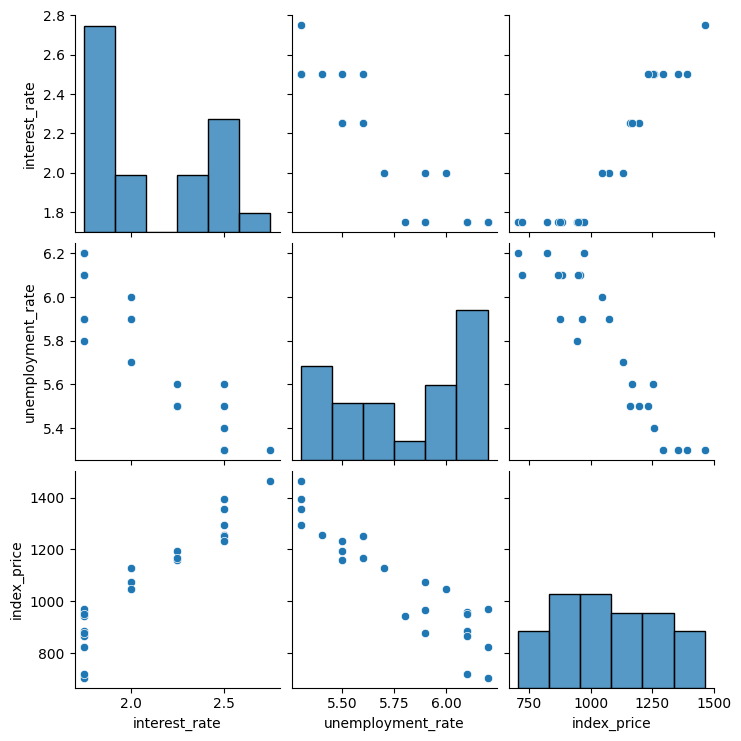

In [7]:
## visualization
import seaborn as sns
sns.pairplot(df_index)


In [8]:
## see correlation to learn how independent values are realting to each other

In [9]:
df_index.corr()

,interest_rate,unemployment_rate,index_price
interest_rate,1.000000,-0.925814,0.935793
unemployment_rate,-0.925814,1.000000,-0.922338
index_price,0.935793,-0.922338,1.000000


Text(0, 0.5, 'unemployment_rate')

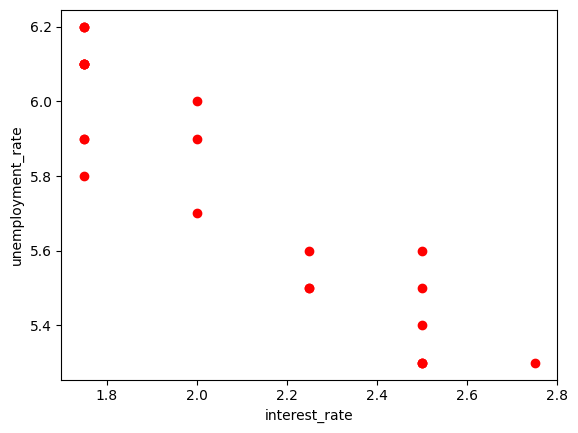

In [10]:
## Visualizing the datapoint more closely
plt.scatter(df_index['interest_rate'],df_index['unemployment_rate'],color='r')
plt.xlabel('interest_rate')
plt.ylabel('unemployment_rate')

In [11]:
## Independent feature and dependent Feature
X = df_index.iloc[:,:-1] # last value bahek agadi ko lincha
y = df_index.iloc[:,-1]

In [12]:
X.head()
y.head()

,index_price
0,1464
1,1394
2,1357
3,1293
4,1256


In [13]:
# train test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

<Axes: xlabel='interest_rate', ylabel='unemployment_rate'>

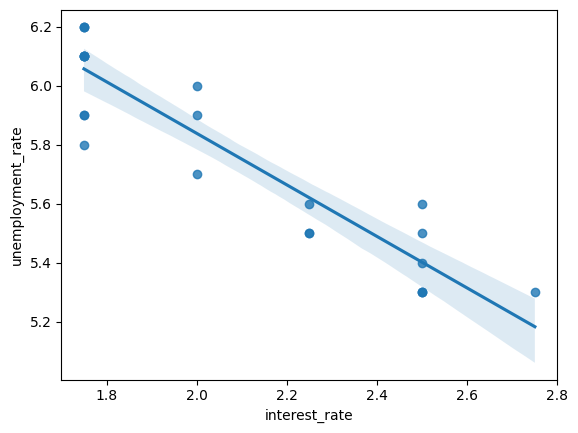

In [14]:
sns.regplot(x=df_index['interest_rate'],
            y=df_index['unemployment_rate'])

<Axes: xlabel='unemployment_rate', ylabel='interest_rate'>

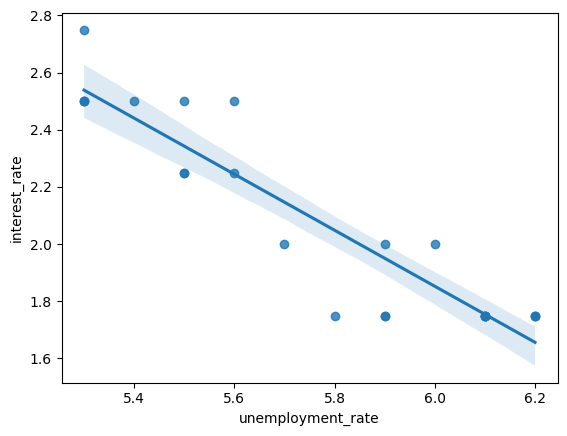

In [15]:
sns.regplot(x=df_index['unemployment_rate'],y=df_index['interest_rate'])

In [16]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test= scaler.transform(X_test)

In [17]:
X_train

array([[-0.89073374,  1.25707872],
       [ 1.35954097, -0.62853936],
       [ 1.35954097, -1.5713484 ],
       [-0.14064217,  0.62853936],
       [-0.89073374,  0.94280904],
       [ 1.35954097, -1.5713484 ],
       [ 1.35954097, -1.25707872],
       [-0.89073374,  1.25707872],
       [-0.89073374,  0.94280904],
       [-0.89073374,  0.31426968],
       [-0.89073374,  0.94280904],
       [ 0.6094494 , -0.94280904],
       [-0.14064217, -0.31426968],
       [-0.89073374,  0.        ],
       [-0.89073374,  0.94280904],
       [ 1.35954097, -0.94280904]])

In [18]:
from sklearn.linear_model import LinearRegression
regression = LinearRegression()


In [23]:
regression.fit(X_train,y_train)


LinearRegression()

### A cross-validation score tells you how well a machine learning model is likely to perform on brand-new, unseen data

In [35]:
from sklearn.model_selection import cross_val_score

# 1000 records bata 900 train 100 test, 900/5 = 180
# test aru train, 180 next, .... last 180 test
#aru train tesle ramro sanga sikna help garcha
## gives 5 different accuracy mse1 , mse2 , mse3 , mse4, mse5
validation_scores = cross_val_score(regression,X_train,y_train,cv=5,
                         scoring='neg_mean_squared_error')

mse_scores = -validation_scores




In [36]:
rmse = np.sqrt(mse_scores)
print(mse_scores)
print(rmse)

[5495.88007512 7496.90768619 9203.37178948 9743.00656351  523.25201601]
[74.13420314 86.58468506 95.93420552 98.7066693  22.87470253]


In [38]:
## Getting those rmse shows how off the predictions are

np.float64(6492.483626060827)

In [39]:
### prediction
y_pred = regression.predict(X_test)


In [40]:
y_pred

array([1192.13083729,  824.23971817, 1400.41971162,  856.16016713,
        992.22505325, 1160.21038833,  920.00106505, 1328.19572341])

In [42]:
#### Performance metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

In [46]:
print("Mean Squared Error:", mse)
print('Root Mean square',np.sqrt(mse))
print("Mean Absolute Error:", mae)
print("R-squared Score:", r2)

Mean Squared Error: 5088.329958294002
Root Mean square 71.3325308558024
Mean Absolute Error: 58.95987629034907
R-squared Score: 0.8640024299625206


** Assumptions **

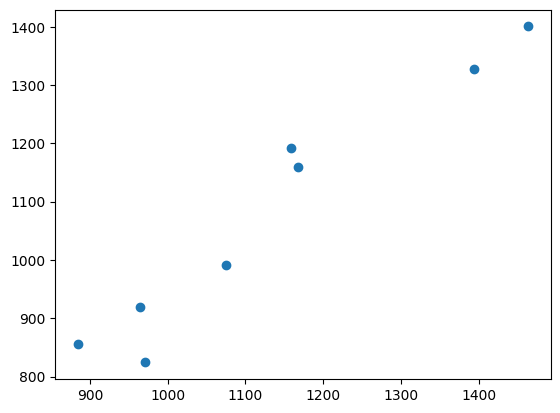

In [48]:
plt.scatter(y_test,y_pred)

In [50]:
residuals = y_test-y_pred
print(residuals)

8     -33.130837
16    146.760282
0      63.580288
18     27.839833
11     82.774947
9       6.789612
13     44.998935
1      65.804277
Name: index_price, dtype: float64


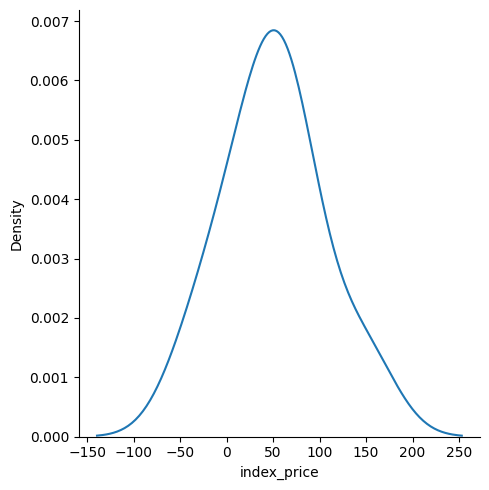

In [51]:
### plot the residuals , paramater is kernel density estimator
import seaborn as sns
sns_val = sns.displot(residuals,kind='kde')

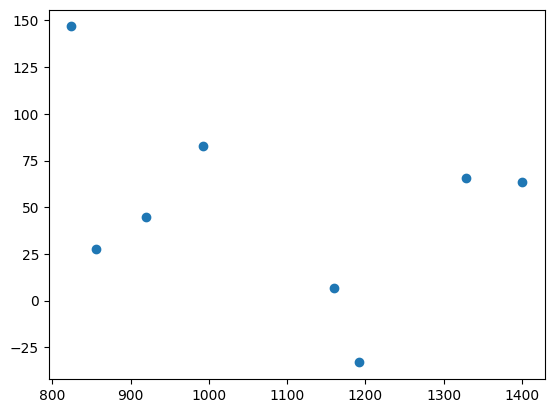

In [52]:
### scatter plot with predictiona and residuals
plt.scatter(y_pred,residuals)

In [54]:
### OLS
import statsmodels.api as sm
model = sm.OLS(y_train,X_train).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:            index_price   R-squared (uncentered):                   0.033
Model:                            OLS   Adj. R-squared (uncentered):             -0.105
Method:                 Least Squares   F-statistic:                             0.2425
Date:                Mon, 28 Sep 2026   Prob (F-statistic):                       0.788
Time:                        04:57:48   Log-Likelihood:                         -133.85
No. Observations:                  16   AIC:                                      271.7
Df Residuals:                      14   BIC:                                      273.3
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1            96.2869    682.952      0.141      0.890   -1368.500    1561.074
x2          -101.5702    682.952     -0.149      0.884   -1566.357    1363.216
==============================================================================
Omnibus:                        0.466   Durbin-Watson:                   0.008
Prob(Omnibus):                  0.792   Jarque-Bera (JB):                0.412
Skew:                          -0.327   Prob(JB):                        0.814
Kurtosis:                       2.563   Cond. No.                         4.70
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [55]:
print(regression.coef_)


[  96.28689501 -101.57024663]
